In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from solver import solve_vlasov_poisson, plot_vp_solution
from optimizer_2 import optimizer, scan_2d

In [2]:
x_res = 2**7
v_res = 2**7
x = np.linspace(0.0, 4.0 * np.pi, x_res)
v = np.linspace(-6.0, 6.0, v_res)
X, V = np.meshgrid(x, v)

a = 0.2
b = 2.0 * np.pi

chi = np.exp(-a * (X - b)**2) * np.sin(X / 2.0)**2
f0 = chi * np.exp(-V**2 / 2.0) / np.sqrt(2.0 * np.pi)
f_desired = f0.copy()
T = 20.0
dt = 0.5
t_res = int(round(T / dt))

In [7]:
modes = np.array([1, 2])
a_initial_guess = np.array([-3.0, -1.5])

coefficients, H, f_final = optimizer(
    f_desired, a_initial_guess, modes, f0, x, v, T, t_res,
    tolerance=1e-5, learning_rate=0.2, max_iter=5000,
)
print("Final Coefficients:", coefficients)

Iteration 0/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.017993310404582765
a1, ..., ak = [-3.  -1.5]
gradient norm = 0.01173300076151254
 
Iteration 1/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.017965412576256376
a1, ..., ak = [-2.99947068 -1.50228612]
gradient norm = 0.012064665755770684
 
Iteration 2/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.017936122125123553
a1, ..., ak = [-2.9989006  -1.50463074]
gradient norm = 0.0122360391326533
 
Iteration 3/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.017904820323502806
a1, ..., ak = [-2.99831166 -1.50700603]
gradient norm = 0.013193303880018896
 
Iteration 4/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.01787006684190507
a1, ..., ak = [-2.99761194 -1.50955022]
gradient norm = 0.013148211163876895
 
Iteration 5/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.017835299474312522
a1, ..., ak = [-2.99691982 -1.51208715]
gradient norm = 0.013298695219485533
 
Iteration 6/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.017800098812208606
a1, ..., ak 

In [8]:
anim = plot_vp_solution(f0, x, v, T, t_res, H)
HTML(anim.to_jshtml())

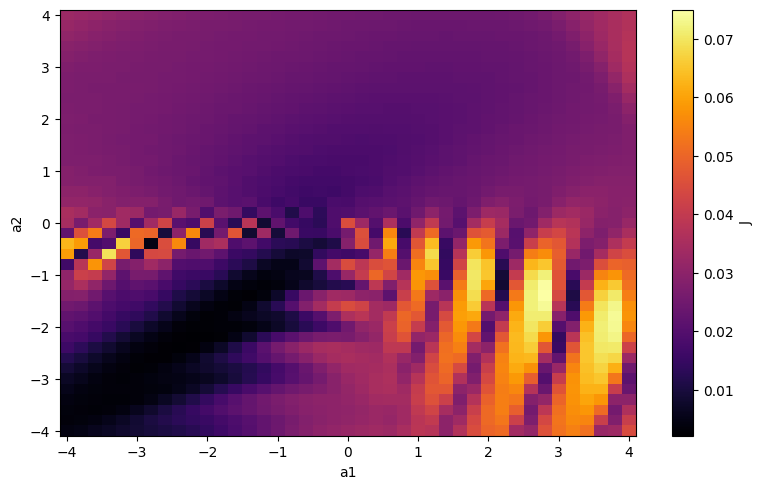

In [5]:
a1_min = -4
a1_max = 4
a2_min = -4
a2_max = 4
a1_step = 0.2
a2_step = 0.2

scan_2d(
    f_desired, a1_min, a1_max, a2_min, a2_max, a1_step, a2_step,
    modes, f0, x, v, T, t_res,
)

In [11]:
modes = np.array([2, 3])
a_initial_guess = np.array([0.5, 2.0])

coefficients, H, f_final = optimizer(
    f_desired, a_initial_guess, modes, f0, x, v, T, t_res,
    tolerance=1e-5, learning_rate=0.2, max_iter=5000,
)
print("Final Coefficients:", coefficients)

Iteration 0/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.01556798630653899
a1, ..., ak = [1. 1.]
gradient norm = 0.05899481981939324
 
Iteration 1/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.014858835647898522
a1, ..., ak = [0.98881926 1.00376918]
gradient norm = 0.06108809470467128
 
Iteration 2/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.014100278648532848
a1, ..., ak = [0.97721227 1.00758334]
gradient norm = 0.06264522899654142
 
Iteration 3/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.013315297248135828
a1, ..., ak = [0.96527527 1.01138928]
gradient norm = 0.06256779577739485
 
Iteration 4/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.012541348446289732
a1, ..., ak = [0.95332727 1.01510875]
gradient norm = 0.061042992028057304
 
Iteration 5/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.01180779969849366
a1, ..., ak = [0.94165213 1.01867818]
gradient norm = 0.059168166829373724
 
Iteration 6/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.011120070975884655
a1, ..., ak = [0.93032049 1.

In [12]:
anim = plot_vp_solution(f0, x, v, T, t_res, H)
HTML(anim.to_jshtml())

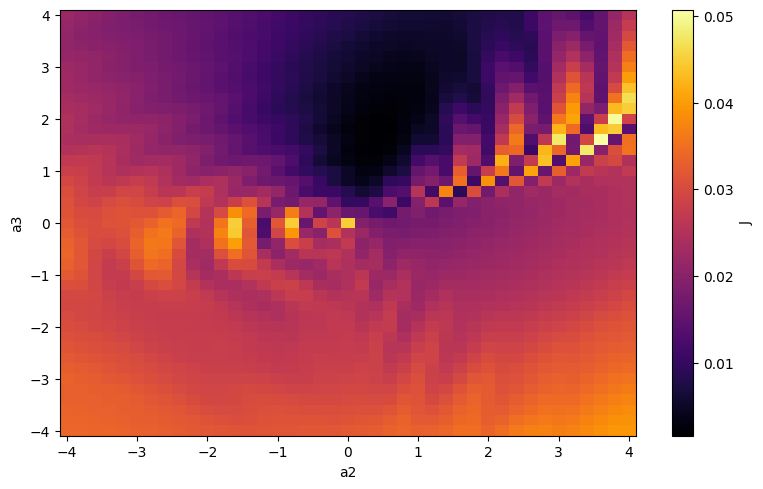

In [13]:
a1_min = -4
a1_max = 4
a2_min = -4
a2_max = 4
a1_step = 0.2
a2_step = 0.2

scan_2d(
    f_desired, a1_min, a1_max, a2_min, a2_max, a1_step, a2_step,
    modes, f0, x, v, T, t_res,
)